# Phase 1 — Data structure, data quality, and patient-level integration

**Project:** TCGA-BRCA (Path B)  
**Unit of analysis:** one patient, identified by the 12-character TCGA patient barcode.  
**Modalities:** clinical variables + one prespecified RNA-expression feature (`A1BG_RNA`).

This notebook is repository-relative and does not contain machine-specific paths. It reads the large molecular file using only the patient identifier and the selected gene, rather than loading all ~52,000 columns into memory.

> Before running: place the five source files in `data/` (see `data/README.md`). If `A1BG_RNA` is not present in the molecular file, change `SELECTED_GENE` below to a documented gene column and use that same feature in Phase 2.

In [1]:
from pathlib import Path
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src").exists():
    raise FileNotFoundError("Open this notebook from the repository (or its notebooks/ folder).")
sys.path.insert(0, str(ROOT / "src"))
from project_utils import find_column, patient_id_from_series, normalize_age, mode_or_nan, save_figure, simplify_stage, clean_stage, consensus_stage_group

DATA = ROOT / "data"
FIG = ROOT / "figures" / "phase1"
OUT = ROOT / "processed"
FIG.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
SELECTED_GENE = "A1BG_RNA"  # Keep identical in Phase 2
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

required_files = ["clinical.tsv", "multiomics.csv"]
missing_files = [f for f in required_files if not (DATA / f).exists()]
if missing_files:
    raise FileNotFoundError(f"Missing required files in {DATA}: {missing_files}. See data/README.md")
print("Repository:", ROOT)
print("Selected molecular feature:", SELECTED_GENE)

Repository: E:\Uni\Statistics\Project
Selected molecular feature: A1BG_RNA


## 1. Load and inspect the clinical data

The raw clinical file may contain multiple rows per patient because nested clinical records can be flattened. We therefore inspect patient multiplicity before constructing a patient-level table; we do not arbitrarily keep the first row.

In [2]:
clinical_raw = pd.read_csv(DATA / "clinical.tsv", sep="\t", low_memory=False)
clinical_source_rows = len(clinical_raw)  # Preserve raw source-row count before ID filtering.
print("Raw clinical shape:", clinical_raw.shape)
print("Columns (first 80):", clinical_raw.columns[:80].tolist())

clinical_id_col = find_column(
    clinical_raw,
    ["cases.submitter_id", "case_submitter_id", "submitter_id", "patient_id", "bcr_patient_barcode"],
    label="clinical patient identifier"
)
age_col = find_column(
    clinical_raw,
    ["demographic.age_at_index", "age_at_index", "age_at_diagnosis", "age"],
    label="age variable"
)
stage_col = find_column(
    clinical_raw,
    ["diagnoses.ajcc_pathologic_stage", "ajcc_pathologic_stage", "pathologic_stage", "tumor_stage"],
    label="pathologic tumor stage"
)
print({"patient_id": clinical_id_col, "age": age_col, "stage": stage_col})

clinical_raw["patient_id"] = patient_id_from_series(clinical_raw[clinical_id_col])
clinical_invalid_ids = int(clinical_raw.patient_id.isna().sum())
clinical_raw["age_years"] = normalize_age(clinical_raw[age_col])
clinical_raw["stage_raw"] = clinical_raw[stage_col].map(clean_stage)
clinical_raw = clinical_raw.dropna(subset=["patient_id"]).copy()
print("Rows with valid TCGA patient ID:", len(clinical_raw))
print("Unique clinical patients:", clinical_raw["patient_id"].nunique())
print("Patients with >1 clinical row:", (clinical_raw.groupby("patient_id").size() > 1).sum())

Raw clinical shape: (5506, 210)
Columns (first 80): ['project.project_id', 'cases.case_id', 'cases.consent_type', 'cases.days_to_consent', 'cases.days_to_lost_to_followup', 'cases.disease_type', 'cases.index_date', 'cases.lost_to_followup', 'cases.primary_site', 'cases.submitter_id', 'demographic.age_at_index', 'demographic.age_is_obfuscated', 'demographic.cause_of_death', 'demographic.cause_of_death_source', 'demographic.country_of_birth', 'demographic.country_of_residence_at_enrollment', 'demographic.days_to_birth', 'demographic.days_to_death', 'demographic.demographic_id', 'demographic.education_level', 'demographic.ethnicity', 'demographic.gender', 'demographic.marital_status', 'demographic.occupation_duration_years', 'demographic.population_group', 'demographic.premature_at_birth', 'demographic.race', 'demographic.submitter_id', 'demographic.vital_status', 'demographic.weeks_gestation_at_birth', 'demographic.year_of_birth', 'demographic.year_of_death', 'diagnoses.adrenal_hormone',

## 2. Clinical data quality and patient-level aggregation

Age is summarized by the median across records for a patient. Tumor stage is summarized by the modal recorded stage; ties are resolved deterministically by the first sorted mode. We retain a conflict count so that this rule is visible and auditable. The stage mode is not a claim that all records agreed.

In [3]:
# Detect conflicting age/stage records before aggregation.
# Missing placeholders such as "--" and "-" have already been normalized to NaN.
conflict_audit = clinical_raw.groupby("patient_id").agg(
    n_records=("patient_id", "size"),
    n_distinct_age=("age_years", lambda x: x.dropna().nunique()),
    n_distinct_stage=("stage_raw", lambda x: x.dropna().nunique()),
)
print("Patients with conflicting age values:", int((conflict_audit.n_distinct_age > 1).sum()))
print("Patients with conflicting valid raw stage values:", int((conflict_audit.n_distinct_stage > 1).sum()))

# Audit valid stage values and whether they imply different binary groups.
stage_conflict_detail = (
    clinical_raw.groupby("patient_id")["stage_raw"]
    .agg(lambda values: sorted(set(values.dropna().astype(str))))
    .reset_index(name="recorded_stage_values")
)
stage_conflict_detail["n_distinct_stage"] = stage_conflict_detail["recorded_stage_values"].str.len()
stage_conflict_detail = stage_conflict_detail[stage_conflict_detail["n_distinct_stage"] > 1].copy()
stage_conflict_detail["recorded_stage_groups"] = stage_conflict_detail["recorded_stage_values"].apply(
    lambda values: sorted({group for group in (simplify_stage(value) for value in values) if pd.notna(group)})
)
stage_conflict_detail["cross_group_conflict"] = stage_conflict_detail["recorded_stage_groups"].str.len() > 1
print("Patients with conflicting valid raw stage values:", len(stage_conflict_detail))
print("Patients whose conflicting values cross Early/Advanced groups:", int(stage_conflict_detail["cross_group_conflict"].sum()))
display(stage_conflict_detail.head(10))

# Keep a descriptive modal raw label, but define the binary stage group by consensus.
# A patient with both Early and Advanced valid records is not forced into either group.
clinical_patient = clinical_raw.groupby("patient_id", as_index=False).agg(
    age_years=("age_years", "median"),
    stage_raw=("stage_raw", mode_or_nan),
    stage_group=("stage_raw", consensus_stage_group),
    n_clinical_records=("patient_id", "size"),
)

# Raw-row duplicate check and patient-level duplicate check are different checks.
print("Exact duplicate raw clinical rows:", int(clinical_raw.duplicated().sum()))
print("Duplicate patient IDs after aggregation:", int(clinical_patient.patient_id.duplicated().sum()))
print("Patient-level clinical shape:", clinical_patient.shape)
display(conflict_audit.describe(include="all"))
display(clinical_patient.head())


Patients with conflicting age values: 0
Patients with conflicting valid raw stage values: 171
Patients with conflicting valid raw stage values: 171
Patients whose conflicting values cross Early/Advanced groups: 5


,patient_id,recorded_stage_values,n_distinct_stage,recorded_stage_groups,cross_group_conflict
0,TCGA-3C-AAAU,"['--, Stage X]",2,[],False
5,TCGA-5L-AAT0,"['--, Stage IIA]",2,[Early],False
6,TCGA-5L-AAT1,"[Stage IIA, Stage IV]",2,"[Advanced, Early]",True
20,TCGA-A1-A0SP,"['--, Stage IIA]",2,[Early],False
23,TCGA-A2-A04P,"['--, Stage IIIC]",2,[Advanced],False
28,TCGA-A2-A04V,"['--, Stage IIA]",2,[Early],False
31,TCGA-A2-A04Y,"[Stage IIA, Stage IIB]",2,[Early],False
32,TCGA-A2-A0CK,"['--, Stage IIIA]",2,[Advanced],False
34,TCGA-A2-A0CM,"['--, Stage IIA]",2,[Early],False
62,TCGA-A2-A0EW,"['--, Stage IIIC]",2,[Advanced],False


Exact duplicate raw clinical rows: 0
Duplicate patient IDs after aggregation: 0
Patient-level clinical shape: (1084, 5)


,n_records,n_distinct_age,n_distinct_stage
count,1084.0,1084.0,1084.000000
mean,5.079336,1.0,1.161439
std,3.024855,0.0,0.378006
min,1.0,1.0,1.000000
25%,3.0,1.0,1.000000
50%,5.0,1.0,1.000000
75%,6.0,1.0,1.000000
max,40.0,1.0,3.000000


,patient_id,age_years,stage_raw,stage_group,n_clinical_records
0,TCGA-3C-AAAU,55.0,Stage X,NaN,4
1,TCGA-3C-AALI,50.0,Stage IIB,Early,3
2,TCGA-3C-AALJ,62.0,Stage IIB,Early,7
3,TCGA-3C-AALK,52.0,Stage IA,Early,6
4,TCGA-4H-AAAK,50.0,Stage IIIA,Advanced,5


## 3. Read the molecular modality efficiently and aggregate to patient

TCGA sample barcodes are mapped to their patient-level barcode. If multiple molecular samples belong to one patient, expression is averaged across that patient's available samples for the selected gene. This is an explicit patient-level aggregation; the number of samples per patient is retained.

In [4]:
# Identify the molecular ID column from its VALUES, not just its column name.
# The first column containing the word "id" may be a UUID and not a TCGA barcode.
mol_header = pd.read_csv(DATA / "multiomics.csv", nrows=0).columns.tolist()
if SELECTED_GENE not in mol_header:
    candidates = [c for c in mol_header if c.upper().endswith("_RNA") or c.upper() in {"BRCA1", "TP53"}]
    raise KeyError(f"Selected gene {SELECTED_GENE!r} not found. Example candidate columns: {candidates[:30]}")

id_keywords = ("submitter", "barcode", "patient", "sample", "case_id", "case id", "aliquot", "id")
id_candidates = [c for c in mol_header if any(k in str(c).lower() for k in id_keywords)]
# Include the first column as a diagnostic fallback, but do not assume it is an ID.
if mol_header and mol_header[0] not in id_candidates:
    id_candidates.append(mol_header[0])
if not id_candidates:
    raise ValueError("No plausible molecular identifier columns found in multiomics.csv.")

# Only candidate identifiers are read for the detection step (950 rows in this dataset).
id_preview = pd.read_csv(DATA / "multiomics.csv", usecols=id_candidates, dtype="string", low_memory=False)
barcode_pattern = r"(TCGA-[A-Z0-9]{2}-[A-Z0-9]{4})"
id_scores = {}
for col in id_candidates:
    parsed = id_preview[col].astype("string").str.upper().str.extract(barcode_pattern, expand=False)
    id_scores[col] = int(parsed.notna().sum())
ranked_ids = sorted(id_scores.items(), key=lambda item: item[1], reverse=True)
print("Molecular identifier candidates (TCGA matches):", ranked_ids[:15])

best_id_col, best_id_matches = ranked_ids[0]
if best_id_matches == 0:
    examples = {c: id_preview[c].dropna().astype(str).head(3).tolist() for c in id_candidates[:8]}
    raise ValueError(
        "No TCGA patient barcode was found in any candidate molecular ID column. "
        "Inspect the candidate values below and identify the mapping key.\n"
        f"Candidate examples: {examples}"
    )

mol_id_col = best_id_col
mol_raw = pd.read_csv(DATA / "multiomics.csv", usecols=[mol_id_col, SELECTED_GENE], low_memory=False)
mol_source_rows = len(mol_raw)
raw_barcode = mol_raw[mol_id_col].astype("string").str.upper().str.strip()
mol_raw["sample_type_code"] = raw_barcode.str.extract(r"TCGA-[A-Z0-9]{2}-[A-Z0-9]{4}-([0-9]{2})", expand=False)
mol_raw["patient_id"] = patient_id_from_series(mol_raw[mol_id_col])
mol_raw[SELECTED_GENE] = pd.to_numeric(mol_raw[SELECTED_GENE], errors="coerce")
invalid_mol_ids = int(mol_raw.patient_id.isna().sum())
mol_raw = mol_raw.dropna(subset=["patient_id"]).copy()
if mol_raw.sample_type_code.notna().any():
    n_before_sample_filter = len(mol_raw)
    mol_raw = mol_raw[(mol_raw.sample_type_code == "01") | mol_raw.sample_type_code.isna()].copy()
    print("Non-primary sample rows excluded:", n_before_sample_filter - len(mol_raw))
print("Selected molecular ID column:", mol_id_col)
print("Source molecular rows:", mol_source_rows)
print("Rows without parsable TCGA patient ID:", invalid_mol_ids)
print("Molecular rows retained for analysis:", len(mol_raw))
molecular_patient = mol_raw.groupby("patient_id", as_index=False).agg(
    **{SELECTED_GENE: (SELECTED_GENE, "mean"), "n_molecular_samples": (SELECTED_GENE, "count")}
)
print("Unique molecular patients:", molecular_patient.patient_id.nunique())
print("Patients with multiple molecular samples:", int((molecular_patient.n_molecular_samples > 1).sum()))
display(molecular_patient.head())


Molecular identifier candidates (TCGA matches): [('Unnamed: 0', 950), ('AFMID_RNA', 0), ('AIDA_RNA', 0), ('ARID1A_RNA', 0), ('ARID1B_RNA', 0), ('ARID2_RNA', 0), ('ARID3A_RNA', 0), ('ARID3B_RNA', 0), ('ARID3C_RNA', 0), ('ARID4A_RNA', 0), ('ARID4B_RNA', 0), ('ARID5A_RNA', 0), ('ARID5B_RNA', 0), ('BID_RNA', 0), ('DIDO1_RNA', 0)]
Non-primary sample rows excluded: 0
Selected molecular ID column: Unnamed: 0
Source molecular rows: 950
Rows without parsable TCGA patient ID: 0
Molecular rows retained for analysis: 950
Unique molecular patients: 944
Patients with multiple molecular samples: 6


,patient_id,A1BG_RNA,n_molecular_samples
0,TCGA-3C-AAAU,0.603430,1
1,TCGA-3C-AALI,0.682114,1
2,TCGA-3C-AALJ,0.450187,1
3,TCGA-3C-AALK,0.276973,1
4,TCGA-4H-AAAK,0.564652,1


## 4. Join modalities and report the participant flow

The inner join defines the multimodal analytic cohort. The table reports raw records, unique patients, and the overlap; the resulting cohort is one row per patient.

In [5]:
# Fail early with a useful message if upstream cells were skipped or failed.
required_state = ["clinical_source_rows", "clinical_raw", "clinical_patient", "mol_source_rows", "mol_raw", "molecular_patient", "stage_conflict_detail"]
missing_state = [name for name in required_state if name not in globals()]
if missing_state:
    raise RuntimeError(
        f"Required Phase 1 variables are missing: {missing_state}. "
        "Restart the kernel and run every code cell from top to bottom; fix the first earlier error before continuing."
    )

n_clin_raw = clinical_source_rows
n_clin_retained = len(clinical_raw)
n_clin_pat = clinical_patient.patient_id.nunique()
n_mol_raw = mol_source_rows
n_mol_retained = len(mol_raw)
n_mol_pat = molecular_patient.patient_id.nunique()

merged = clinical_patient.merge(molecular_patient, on="patient_id", how="inner", validate="one_to_one")
assert merged.patient_id.is_unique, "Patient-level table must have one row per patient."
flow = pd.DataFrame([
    ["Clinical", n_clin_raw, n_clin_retained, n_clin_pat],
    ["Molecular", n_mol_raw, n_mol_retained, n_mol_pat],
    ["Multimodal inner-join cohort", len(merged), len(merged), merged.patient_id.nunique()],
], columns=["Dataset / stage", "Source records", "Records retained", "Unique patients"])
display(flow)
print("Clinical patients without molecular data:", n_clin_pat - merged.patient_id.nunique())
print("Molecular patients without clinical data:", n_mol_pat - merged.patient_id.nunique())

missingness_parts = []
for modality, table, variables in [
    ("Clinical patient-level", clinical_patient, ["age_years", "stage_raw", "stage_group"]),
    ("Molecular patient-level", molecular_patient, [SELECTED_GENE]),
    ("Merged cohort", merged, ["age_years", "stage_raw", "stage_group", SELECTED_GENE]),
]:
    for variable in variables:
        missing_n = int(table[variable].isna().sum())
        missingness_parts.append([modality, variable, len(table), missing_n, 100*missing_n/len(table) if len(table) else np.nan])
missingness = pd.DataFrame(missingness_parts, columns=["modality", "variable", "N", "missing_n", "missing_percent"])
display(missingness)
print("Clinical rows with invalid patient ID:", clinical_invalid_ids)
merged.to_csv(OUT / "phase1_patient_level.csv", index=False)
flow.to_csv(OUT / "phase1_data_flow.csv", index=False)
missingness.to_csv(OUT / "phase1_missingness.csv", index=False)
stage_conflict_detail.to_csv(OUT / "phase1_stage_conflicts.csv", index=False)
print("Saved:", OUT / "phase1_patient_level.csv")

,Dataset / stage,Source records,Records retained,Unique patients
0,Clinical,5506,5506,1084
1,Molecular,950,950,944
2,Multimodal inner-join cohort,936,936,936


Clinical patients without molecular data: 148
Molecular patients without clinical data: 8


,modality,variable,N,missing_n,missing_percent
0,Clinical patient-level,age_years,1084,0,0.000000
1,Clinical patient-level,stage_raw,1084,0,0.000000
2,Clinical patient-level,stage_group,1084,28,2.583026
3,Molecular patient-level,A1BG_RNA,944,0,0.000000
4,Merged cohort,age_years,936,0,0.000000
5,Merged cohort,stage_raw,936,0,0.000000
6,Merged cohort,stage_group,936,25,2.670940
7,Merged cohort,A1BG_RNA,936,0,0.000000


Clinical rows with invalid patient ID: 0
Saved: E:\Uni\Statistics\Project\processed\phase1_patient_level.csv


## 5. Descriptive statistics and visualizations

These are descriptive summaries of the observed TCGA-BRCA cohort. IQR-flagged values are statistical flags, not automatically erroneous observations; no record is deleted solely for being an outlier.

Age (years):


,age_years
count,936.000000
mean,58.260684
std,13.058912
min,26.000000
25%,49.000000
50%,58.000000
75%,67.000000
max,89.000000


IQR fences: [22.00, 94.00], flagged observations: 0


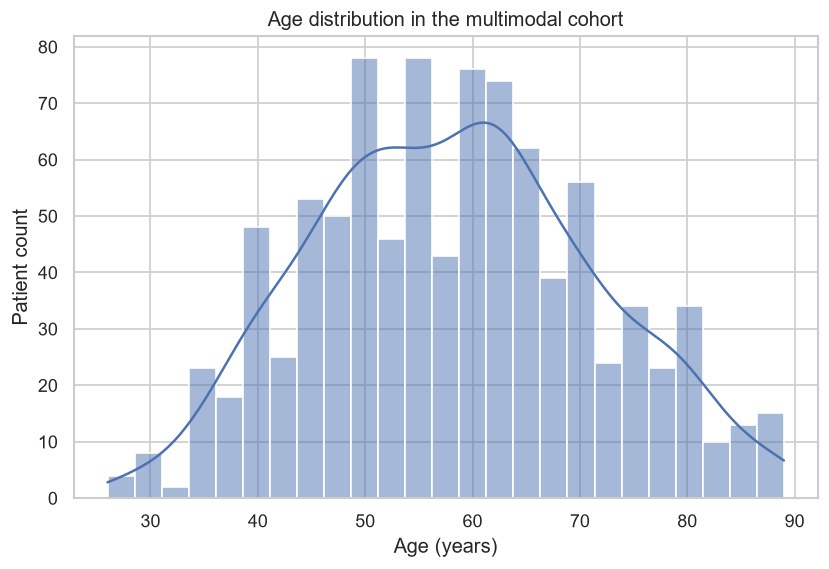

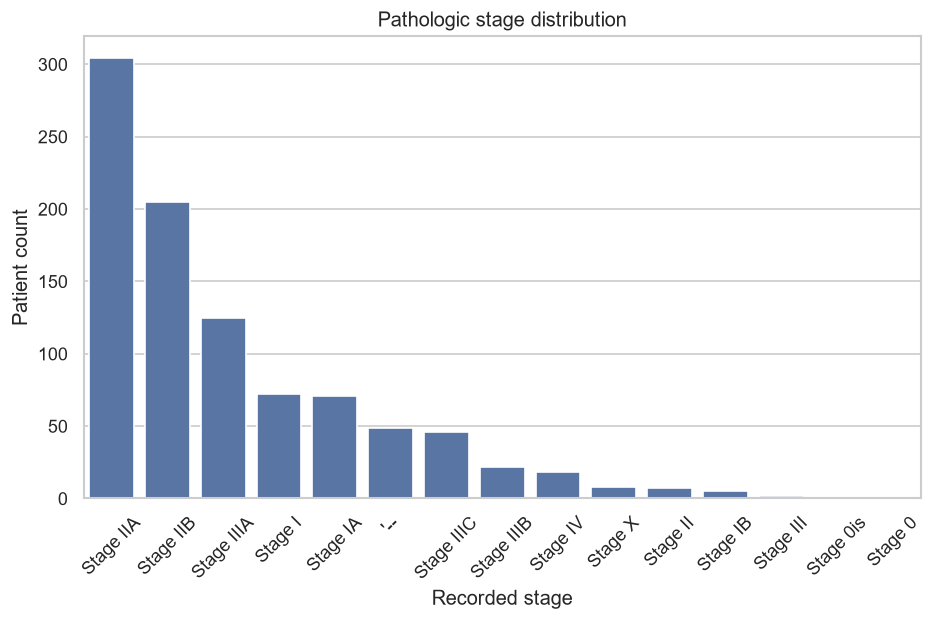

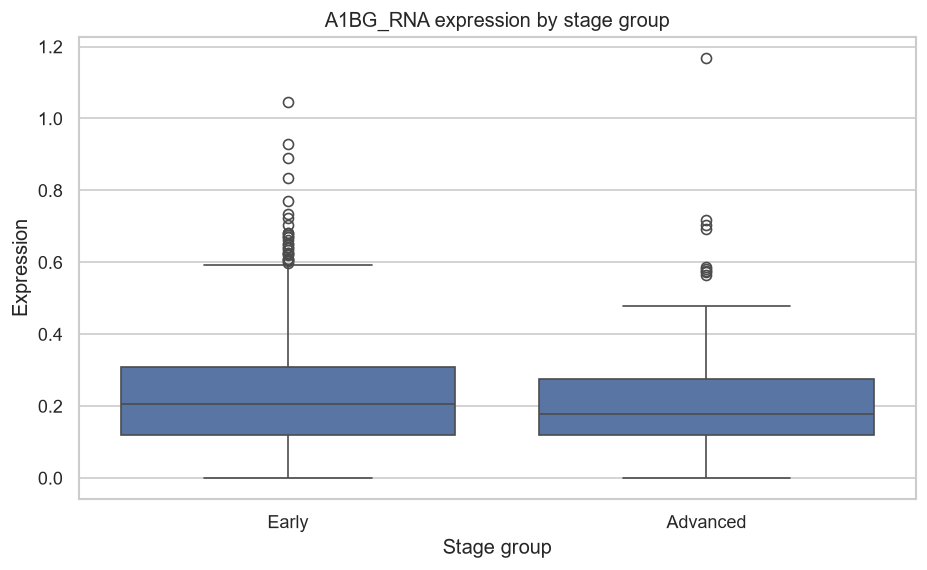

In [6]:
if "merged" not in globals():
    raise RuntimeError("The multimodal table 'merged' does not exist. Run all previous Phase 1 cells successfully first.")
# Age summary
age = merged.age_years.dropna()
print("Age (years):")
display(age.describe().to_frame("age_years"))
if len(age):
    q1, q3 = age.quantile([.25, .75]); iqr = q3-q1
    age_out = age[(age < q1-1.5*iqr) | (age > q3+1.5*iqr)]
    print(f"IQR fences: [{q1-1.5*iqr:.2f}, {q3+1.5*iqr:.2f}], flagged observations: {len(age_out)}")

fig, ax = plt.subplots(figsize=(8,5))
sns.histplot(age, bins=25, kde=True, ax=ax)
ax.set(title="Age distribution in the multimodal cohort", xlabel="Age (years)", ylabel="Patient count")
save_figure(fig, FIG / "age_distribution.png"); plt.show()

stage_counts = merged.stage_raw.fillna("Missing").value_counts()
fig, ax = plt.subplots(figsize=(9,5))
sns.barplot(x=stage_counts.index, y=stage_counts.values, ax=ax)
ax.set(title="Pathologic stage distribution", xlabel="Recorded stage", ylabel="Patient count")
ax.tick_params(axis="x", rotation=45)
save_figure(fig, FIG / "tumor_stage_distribution.png"); plt.show()

fig, ax = plt.subplots(figsize=(9,5))
sns.boxplot(data=merged, x="stage_group", y=SELECTED_GENE, order=["Early", "Advanced"], ax=ax)
ax.set(title=f"{SELECTED_GENE} expression by stage group", xlabel="Stage group", ylabel="Expression")
save_figure(fig, FIG / "molecular_vs_stage_boxplot.png"); plt.show()

## 6. Phase 1 interpretation checklist

Before writing the final report, record the printed counts and address all of the following:

- The observational unit is a patient, not a tissue sample or a flattened clinical row.
- Explain the patient barcode mapping and the molecular-sample aggregation rule.
- Report clinical and molecular counts before and after matching.
- Report missingness separately for age, raw stage, stage group, and expression.
- Discuss conflicts in repeated clinical records and the chosen median/mode rules.
- Interpret IQR flags as potential unusual observations, not proof of data errors.
- State the exact data source and download date in the report. Do not describe methylation as an analyzed modality unless it is actually included.

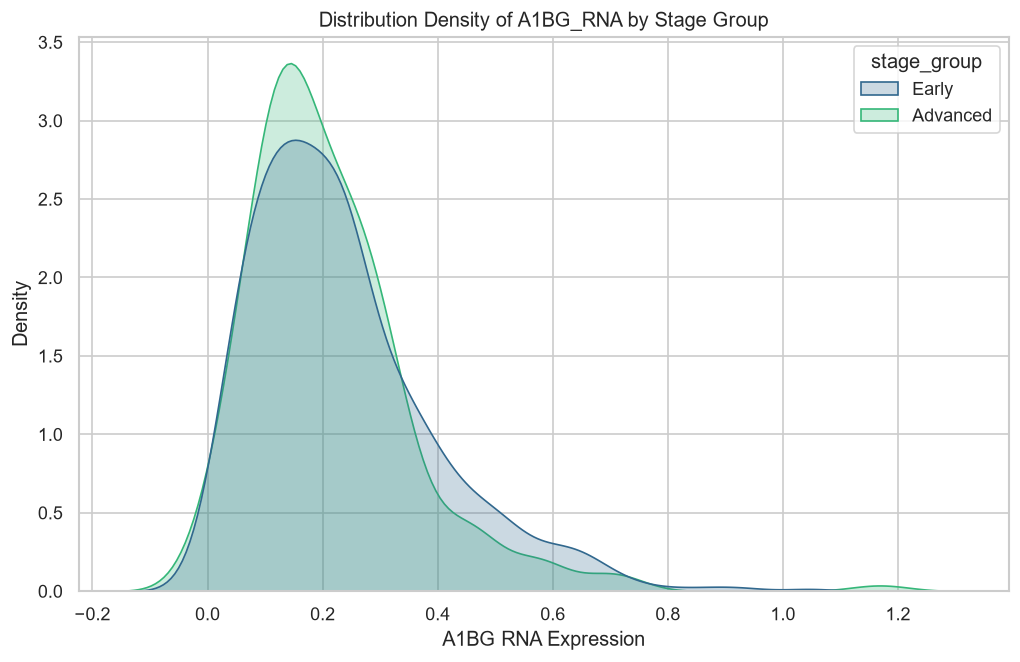

In [9]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. پیدا کردن مسیر پوشه جاری نوت‌بوک (notebooks)
base_dir = os.getcwd() 

# 2. رفتن به یک سطح بالاتر (پوشه اصلی پروژه) و سپس رفتن به پوشه مورد نظر
# چون نوت‌بوک در /notebooks است، با '..' به پوشه ریشه برمی‌گردیم
file_path = os.path.join(base_dir, '..', 'processed', 'phase1_patient_level.csv')
output_dir = os.path.join(base_dir, '..', 'figures', 'phase1')

# اطمینان از وجود مسیر ذخیره‌سازی
os.makedirs(output_dir, exist_ok=True)

# 3. بارگذاری داده
df_merged = pd.read_csv(file_path)

# 4. رسم نمودار
plt.figure(figsize=(10, 6))
sns.kdeplot(
    data=df_merged, 
    x='A1BG_RNA', 
    hue='stage_group', 
    fill=True, 
    common_norm=False, 
    palette='viridis'
)

plt.title('Distribution Density of A1BG_RNA by Stage Group')
plt.xlabel('A1BG RNA Expression')
plt.ylabel('Density')

# 5. ذخیره سازی
plt.savefig(os.path.join(output_dir, 'gene_density_by_stage.png'), dpi=300, bbox_inches='tight')
plt.show()
